C:\Users\iva.svecova\AppData\Local\Temp\ipykernel_37704\3607091267.py:33: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


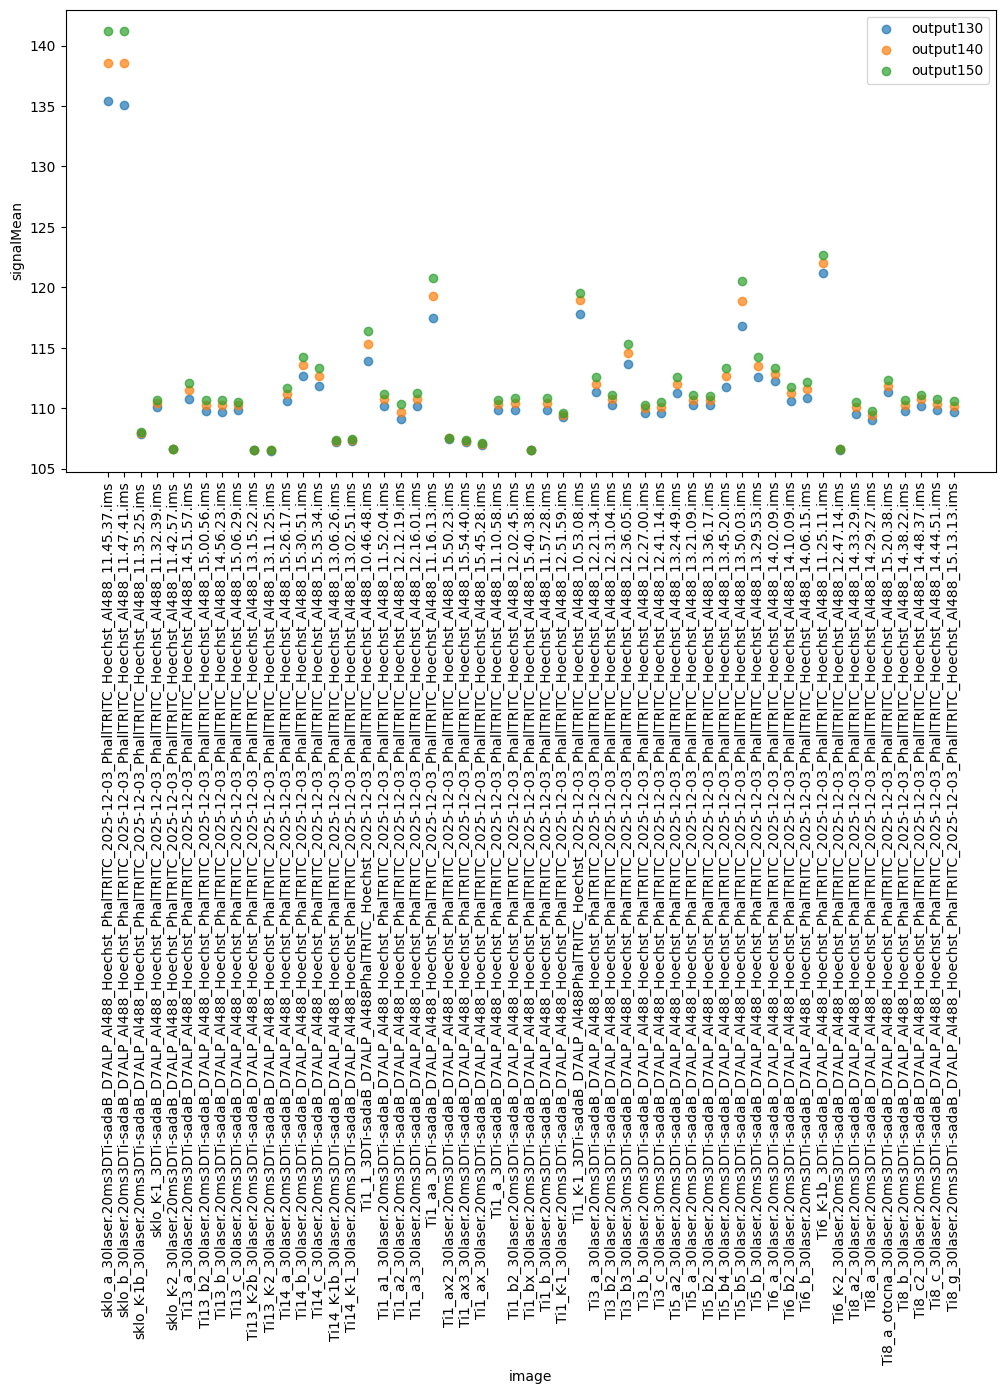

In [1]:
import os
import pandas as pd

import matplotlib.pyplot as plt

# Load all CSVs from subfolders
data_frames = []
output_folder = 'output'

for subfolder in os.listdir(output_folder):
    subfolder_path = os.path.join(output_folder, subfolder)
    if os.path.isdir(subfolder_path):
        for file in os.listdir(subfolder_path):
            if file.endswith('.csv'):
                file_path = os.path.join(subfolder_path, file)
                df = pd.read_csv(file_path)
                df['subfolder'] = subfolder
                data_frames.append(df)

# Combine all DataFrames
combined_df = pd.concat(data_frames, ignore_index=True)

# Create scatterplot
plt.figure(figsize=(12, 6))
for subfolder in combined_df['subfolder'].unique():
    subset = combined_df[combined_df['subfolder'] == subfolder]
    plt.scatter(subset['image'], subset['signalMean'], label=subfolder, alpha=0.7)

plt.xlabel('image')
plt.ylabel('signalMean')
plt.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

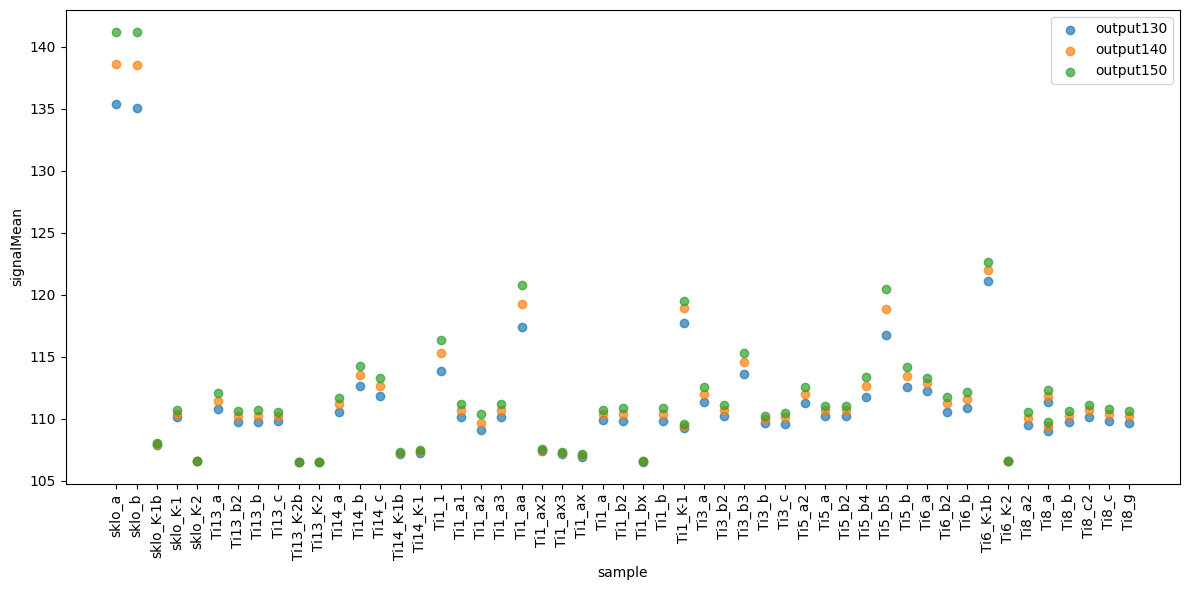

In [3]:
combined_df['sample'] = combined_df['sampleType'] + '_' + combined_df['sampleReplicate']

# Create scatterplot
plt.figure(figsize=(12, 6))
for subfolder in combined_df['subfolder'].unique():
    subset = combined_df[combined_df['subfolder'] == subfolder]
    plt.scatter(subset['sample'], subset['signalMean'], label=subfolder, alpha=0.7)

plt.xlabel('sample')
plt.ylabel('signalMean')
plt.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
